<a href="https://colab.research.google.com/github/arnabameer/CVPR/blob/main/23_51169_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q kagglehub torchsummary scikit-learn


In [ ]:

from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader, random_split

import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt

from torch.optim import SGD, Adam
from torchsummary import summary

from sklearn.metrics import classification_report, confusion_matrix

%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)


Device: cuda


In [ ]:

import kagglehub

path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print("Path to dataset files:", path)


Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


In [ ]:

import os

train_folder = path + "/seg_train/seg_train"
test_folder = path + "/seg_test/seg_test"

print("Training Folder Exists:", os.path.exists(train_folder))
print("Testing Folder Exists:", os.path.exists(test_folder))

print("Training Classes:", os.listdir(train_folder))


Training Folder Exists: True
Testing Folder Exists: True
Training Classes: ['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


In [ ]:


size = 32


train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor()
])


val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

print("Data Preprocessing Completed!")


Data Preprocessing Completed!


In [ ]:


train_data = datasets.ImageFolder(
    train_folder,
    transform=train_transform
)


val_test_data = datasets.ImageFolder(
    test_folder,
    transform=val_transform
)

print("Training Dataset:", len(train_data))
print("Testing Dataset:", len(val_test_data))

print("Classes:", train_data.classes)
print("Number of Classes:", len(train_data.classes))


Training Dataset: 14034
Testing Dataset: 3000
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of Classes: 6


In [ ]:

train_data = datasets.ImageFolder(
    train_folder,
    transform=train_transform
)


val_test_data = datasets.ImageFolder(
    test_folder,
    transform=val_transform
)

print("Training Dataset:", len(train_data))
print("Testing Dataset:", len(val_test_data))

print("Classes:", train_data.classes)
print("Number of Classes:", len(train_data.classes))


Training Dataset: 14034
Testing Dataset: 3000
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Number of Classes: 6


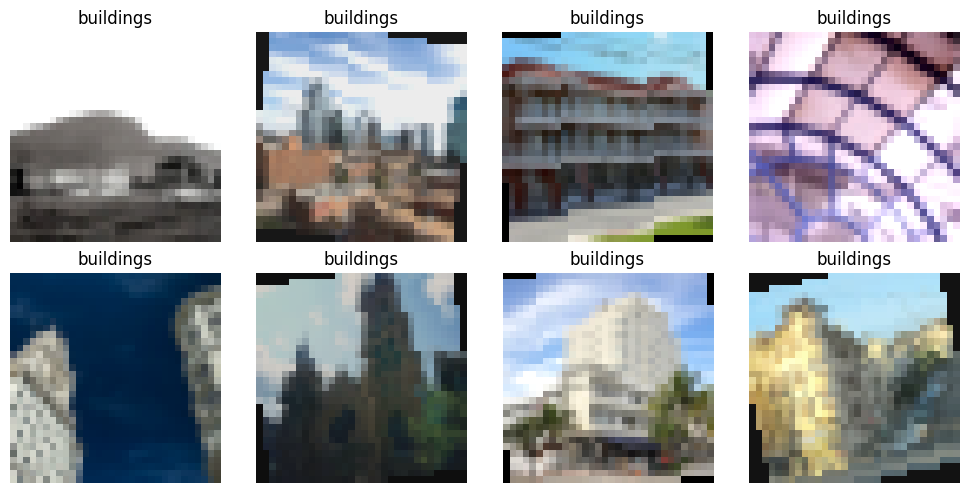

In [ ]:

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Hyperparameters
batch_size = 32
learning_rate = 0.001
epoch_number = 10

# Training DataLoader
trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

# Validation DataLoader
val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

# Testing DataLoader
test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training Batches:", len(trn_dl))
print("Validation Batches:", len(val_dl))
print("Testing Batches:", len(test_dl))


NameError: name 'val_data' is not defined

In [ ]:


from torch.utils.data import random_split, DataLoader


SEED = 42

val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)


trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)


val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)


test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training Images:", len(train_data))
print("Validation Images:", len(val_data))
print("Testing Images:", len(test_data))

print("Training Batches:", len(trn_dl))
print("Validation Batches:", len(val_dl))
print("Testing Batches:", len(test_dl))

print("All DataLoaders Created Successfully!")


Training Images: 14034
Validation Images: 1500
Testing Images: 1500
Training Batches: 439
Validation Batches: 47
Testing Batches: 47
All DataLoaders Created Successfully!


In [ ]:

def get_model():

    model = nn.Sequential(

        # First Convolution Layer
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Second Convolution Layer
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Fully Connected Layers
        nn.Flatten(),

        nn.Linear(128 * 6 * 6, 256),
        nn.ReLU(),

        nn.Linear(256, len(train_data.classes))

    ).to(device)

    # Loss Function
    loss_fn = nn.CrossEntropyLoss()

    # Optimizer
    optimizer = Adam(
        model.parameters(),
        lr=learning_rate
    )

    return model, loss_fn, optimizer


model, loss_fn, optimizer = get_model()

print(model)


Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4608, out_features=256, bias=True)
  (8): ReLU()
  (9): Linear(in_features=256, out_features=6, bias=True)
)


In [ ]:

summary(model, input_size=(3, 32, 32))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 6]           1,542
Total params: 1,257,094
Trainable params: 1,257,094
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.80
Estimat

In [ ]:

def train_one_epoch(data_loader, model, loss_fn, optimizer):

    model.train()

    epoch_losses = []
    epoch_accuracies = []

    for x, y in data_loader:

        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        prediction = model(x)

        batch_loss = loss_fn(prediction, y)

        batch_loss.backward()

        optimizer.step()

        epoch_losses.append(batch_loss.item())

        is_correct = (
            prediction.argmax(-1) == y
        ).detach().cpu().tolist()

        epoch_accuracies.extend(is_correct)

    return np.mean(epoch_losses), np.mean(epoch_accuracies)


print("Training Function Ready!")


Training Function Ready!


In [ ]:

@torch.no_grad()
def validation(data_loader, model, loss_fn):

    model.eval()

    val_losses = []
    val_accuracies = []

    for x, y in data_loader:

        x = x.to(device)
        y = y.to(device)

        prediction = model(x)

        batch_loss = loss_fn(prediction, y)

        val_losses.append(batch_loss.item())

        is_correct = (
            prediction.argmax(-1) == y
        ).cpu().tolist()

        val_accuracies.extend(is_correct)

    return np.mean(val_losses), np.mean(val_accuracies)


print("Validation Function Ready!")


Validation Function Ready!


In [ ]:

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(epoch_number):

    epoch_loss, epoch_accuracy = train_one_epoch(
        trn_dl,
        model,
        loss_fn,
        optimizer
    )

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(
        val_dl,
        model,
        loss_fn
    )

    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    print(
        f"Epoch [{epoch+1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f}"
        f" | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f}"
        f" | Val Accuracy: {v_acc*100:.2f}%"
    )


Epoch [1/10] | Train Loss: 1.1113 | Train Accuracy: 56.77% | Val Loss: 0.9032 | Val Accuracy: 66.00%
Epoch [2/10] | Train Loss: 0.8650 | Train Accuracy: 67.89% | Val Loss: 0.7752 | Val Accuracy: 72.47%
Epoch [3/10] | Train Loss: 0.7885 | Train Accuracy: 70.53% | Val Loss: 0.7706 | Val Accuracy: 70.67%
Epoch [4/10] | Train Loss: 0.7345 | Train Accuracy: 72.97% | Val Loss: 0.7504 | Val Accuracy: 71.27%
Epoch [5/10] | Train Loss: 0.6892 | Train Accuracy: 74.34% | Val Loss: 0.6651 | Val Accuracy: 76.13%
Epoch [6/10] | Train Loss: 0.6623 | Train Accuracy: 75.69% | Val Loss: 0.6943 | Val Accuracy: 73.33%
Epoch [7/10] | Train Loss: 0.6306 | Train Accuracy: 76.78% | Val Loss: 0.6207 | Val Accuracy: 77.13%
Epoch [8/10] | Train Loss: 0.6038 | Train Accuracy: 77.89% | Val Loss: 0.6265 | Val Accuracy: 77.27%
Epoch [9/10] | Train Loss: 0.5836 | Train Accuracy: 78.67% | Val Loss: 0.6139 | Val Accuracy: 77.73%
Epoch [10/10] | Train Loss: 0.5589 | Train Accuracy: 79.64% | Val Loss: 0.6302 | Val Accura

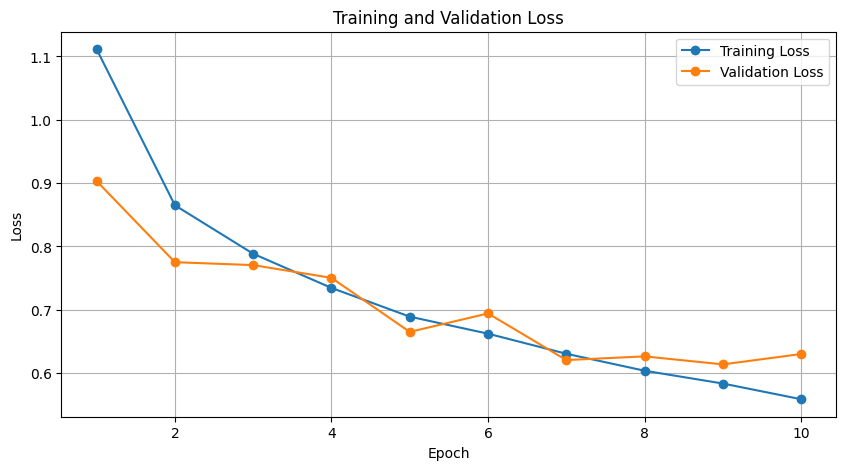

In [ ]:

epochs = np.arange(epoch_number) + 1

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()


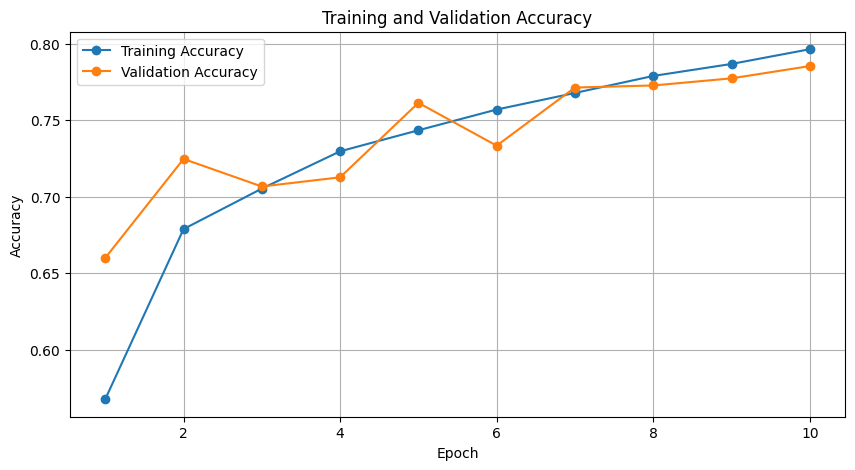

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()


In [ ]:

test_loss, test_acc = validation(
    test_dl,
    model,
    loss_fn
)

print("Test Loss:", test_loss)

print(
    "Test Accuracy:",
    test_acc * 100,
    "%"
)


Test Loss: 0.6483987905877702
Test Accuracy: 77.8 %


In [ ]:

@torch.no_grad()
def get_predictions(data_loader, model):

    model.eval()

    all_predictions = []
    all_labels = []

    for x, y in data_loader:

        x = x.to(device)

        outputs = model(x)

        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(y.numpy())

    return np.array(all_labels), np.array(all_predictions)


y_true, y_pred = get_predictions(test_dl, model)

print("Classification Report:")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=train_data.classes,
        zero_division=0
    )
)

print("Confusion Matrix:")

print(
    confusion_matrix(y_true, y_pred)
)


Classification Report:
              precision    recall  f1-score   support

   buildings       0.68      0.73      0.70       210
      forest       0.82      0.95      0.88       234
     glacier       0.76      0.79      0.77       285
    mountain       0.81      0.69      0.74       254
         sea       0.79      0.72      0.75       260
      street       0.82      0.79      0.81       257

    accuracy                           0.78      1500
   macro avg       0.78      0.78      0.78      1500
weighted avg       0.78      0.78      0.78      1500

Confusion Matrix:
[[154  18   3   6   3  26]
 [  2 223   0   2   1   6]
 [ 10   1 225  23  19   7]
 [ 10   4  37 174  27   2]
 [ 22   7  30  10 187   4]
 [ 29  20   3   0   1 204]]


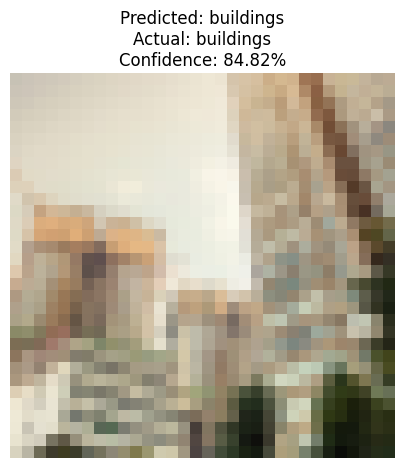

In [ ]:

test_img, label = test_data[0]

img = test_img.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():

    output = model(img)

    probabilities = torch.softmax(output, dim=1)

    confidence, index = probabilities.max(dim=1)


plt.figure(figsize=(5, 5))

plt.imshow(test_img.permute(1, 2, 0))

plt.title(
    f"Predicted: {train_data.classes[index.item()]}\n"
    f"Actual: {train_data.classes[label]}\n"
    f"Confidence: {confidence.item()*100:.2f}%"
)

plt.axis("off")

plt.show()


In [ ]:

model_path = "intel_custom_cnn_model.pth"

torch.save(
    model.state_dict(),
    model_path
)

print("Model Saved Successfully!")

import os

print(
    "Model Size:",
    round(os.path.getsize(model_path) / (1024*1024), 2),
    "MB"
)


Model Saved Successfully!
Model Size: 4.8 MB


In [ ]:

saved_model, _, _ = get_model()

saved_model.load_state_dict(
    torch.load(
        model_path,
        map_location=device
    )
)

saved_model.eval()

print("Model Loaded Successfully!")

summary(
    saved_model,
    input_size=(3, 32, 32)
)


Model Loaded Successfully!
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 6]           1,542
Total params: 1,257,094
Trainable params: 1,257,094
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Par

In [ ]:

from google.colab import files

files.download("intel_custom_cnn_model.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>